# Лабораторная 3. Морфологические преобразования

**Задание**

Выделить проблемные зубья у шестерёнки.

* использовать только морфологические операции для бинарных изображений;
* `Erode` — размывание (операция сужения), `Dilate` — растягивание (операция расширения), OpenCV.

Схема — по лекции 4 (слайды 47–48), описание: Shapiro, Stockman, «Computer Vision», рис. 3.15.

## Импорты и пути

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

BASE_DIR = next((p for p in (Path("assets"), Path("lab3/assets")) if p.is_dir()), Path("assets"))

## Бинаризация

порог Оцу: 125


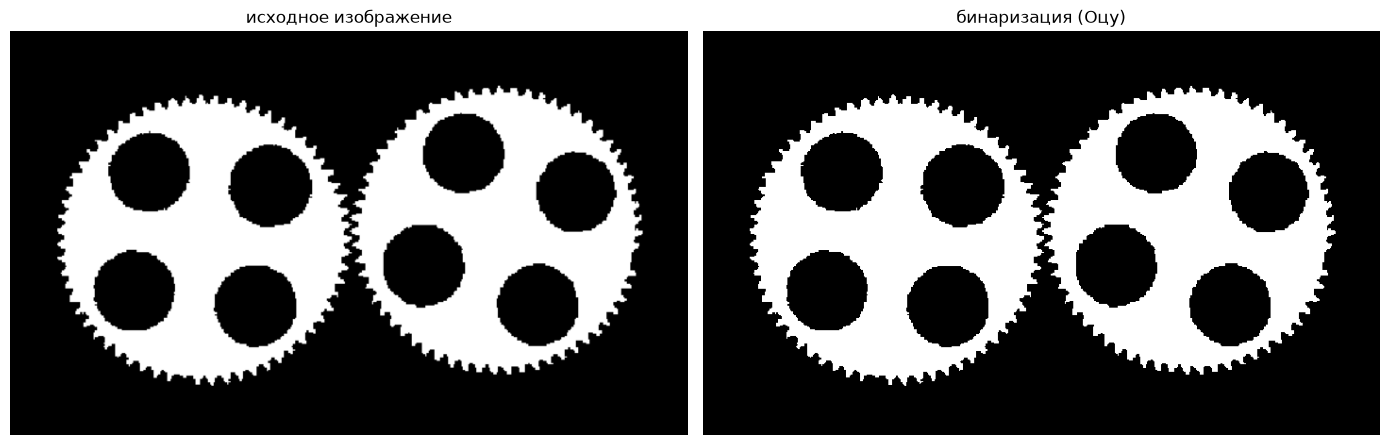

In [ ]:
image_path = str(BASE_DIR / "Шестеренки.png")

image = cv2.imread(image_path, cv2.IMREAD_COLOR_RGB)
if image is None:
    raise FileNotFoundError(image_path)

gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
threshold, B = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"порог Оцу: {threshold:.0f}")

plt.figure(figsize=(14, 4.5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("исходное изображение")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(B, "gray", vmin=0, vmax=255)
plt.title("бинаризация (Оцу)")
plt.axis("off")

plt.tight_layout()
plt.show()

## Структурные элементы

In [ ]:
def disk(r):
    """Диск радиуса r."""
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))


def octagon(r):
    """Восьмиугольник радиуса r."""
    y, x = np.mgrid[-r:r + 1, -r:r + 1]
    return ((np.maximum(abs(x), abs(y)) <= r) & (abs(x) + abs(y) <= int(1.42 * r))).astype(np.uint8)


def ring(r_in, r_out):
    """Кольцо от r_in до r_out."""
    y, x = np.mgrid[-r_out:r_out + 1, -r_out:r_out + 1]
    d = np.hypot(x, y)
    return ((d >= r_in) & (d <= r_out)).astype(np.uint8)


def pad_to(kernel, size):
    """Вписать ядро в квадрат size x size по центру."""
    out = np.zeros((size, size), np.uint8)
    offset = (size - kernel.shape[0]) // 2
    out[offset:offset + kernel.shape[0], offset:offset + kernel.shape[1]] = kernel
    return out


def hit_miss(img, foreground, background):
    """Попадание-пропуск: эрозия объекта по одной части шаблона и эрозия фона по другой."""
    size = foreground.shape[0]
    return cv2.bitwise_and(cv2.erode(img, foreground), cv2.erode(255 - img, pad_to(background, size)))


# Радиусы взяты из геометрии изображения:
# отверстия R ~ 43, впадины R ~ 142, верхушки R ~ 153, шаг между верхушками ~ 15 px.
hole_ring = (47, 53)   # кольцо чуть больше отверстия
hole_bg = 38           # внутренность кольца попадает на фон отверстия
hole_mask = 48         # восьмиугольник чуть больше отверстия
gear_body = 30         # диск снимает зубья, но сохраняет форму тела
spacer = 4             # выход от тела к основанию зубьев
width = 3              # ещё выход — до верхушек
tip_spacing = 7        # перекрывает промежуток между верхушками соседних зубьев
defect_cue = 8         # размер подсветки дефекта

## Центры отверстий

центров отверстий: 8


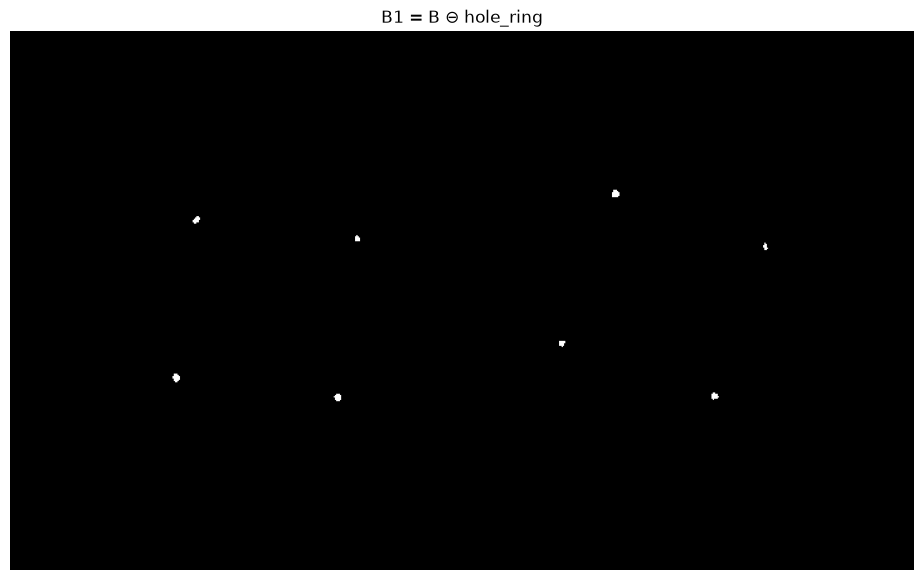

In [ ]:
B1 = hit_miss(B, ring(*hole_ring), disk(hole_bg))
print("центров отверстий:", cv2.connectedComponentsWithStats(B1, 8)[0] - 1)

plt.figure(figsize=(12, 7))
plt.imshow(B1, "gray", vmin=0, vmax=255)
plt.title("B1 = B ⊖ hole_ring")
plt.axis("off")
plt.show()

## Заполнение отверстий

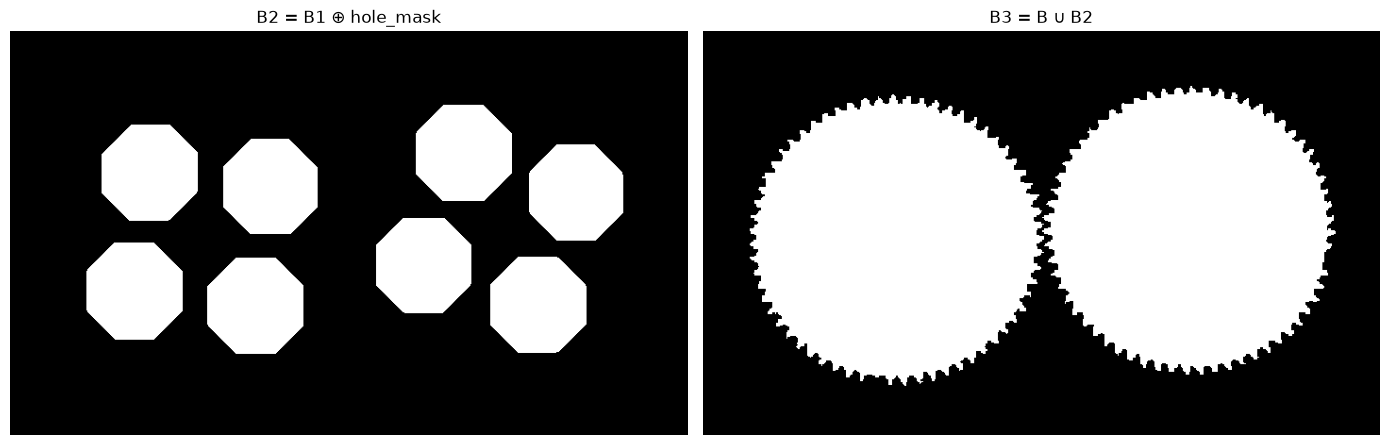

In [ ]:
B2 = cv2.dilate(B1, octagon(hole_mask))
B3 = cv2.bitwise_or(B, B2)

plt.figure(figsize=(14, 4.5))

plt.subplot(1, 2, 1)
plt.imshow(B2, "gray", vmin=0, vmax=255)
plt.title("B2 = B1 ⊕ hole_mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(B3, "gray", vmin=0, vmax=255)
plt.title("B3 = B ∪ B2")
plt.axis("off")

plt.tight_layout()
plt.show()

## Тело шестерни

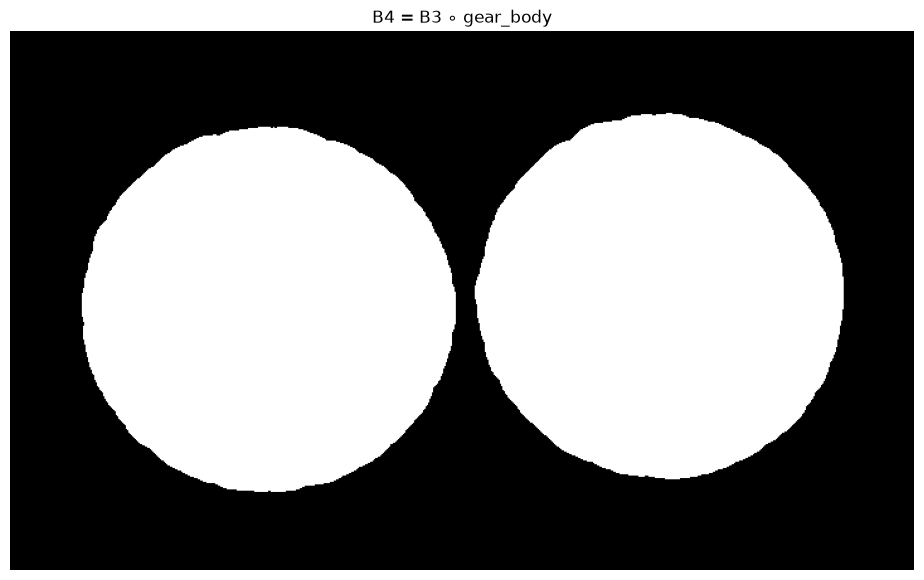

In [ ]:
B4 = cv2.morphologyEx(B3, cv2.MORPH_OPEN, disk(gear_body))

plt.figure(figsize=(12, 7))
plt.imshow(B4, "gray", vmin=0, vmax=255)
plt.title("B4 = B3 ∘ gear_body")
plt.axis("off")
plt.show()

## Семплирующее кольцо

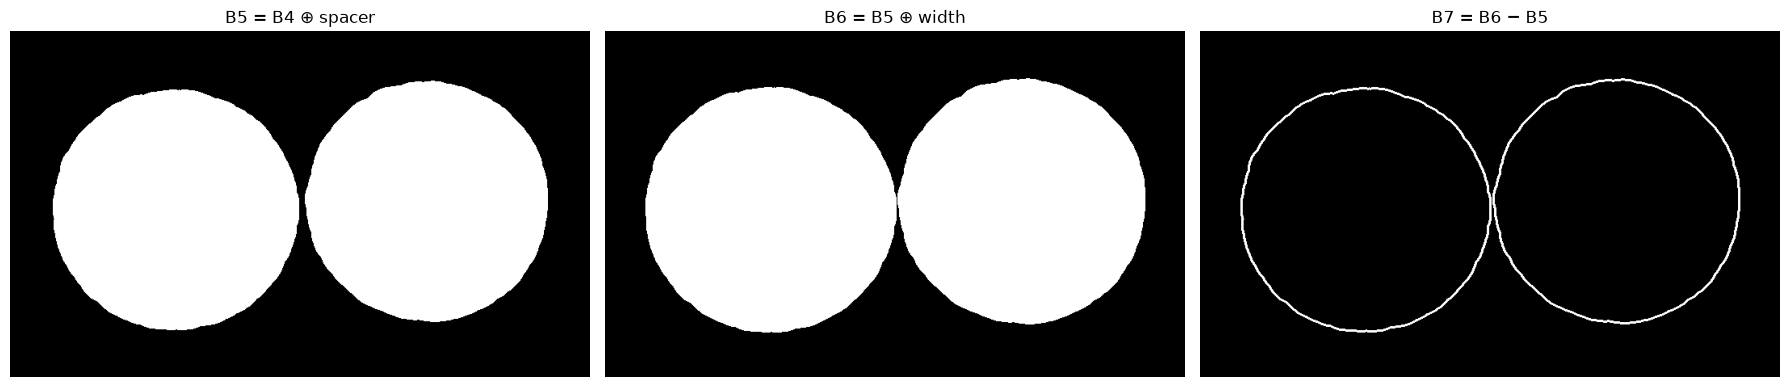

In [ ]:
B5 = cv2.dilate(B4, disk(spacer))
B6 = cv2.dilate(B5, disk(width))
B7 = cv2.subtract(B6, B5)

plt.figure(figsize=(18, 4))

for i, (title, img) in enumerate([("B5 = B4 ⊕ spacer", B5),
                                  ("B6 = B5 ⊕ width", B6),
                                  ("B7 = B6 − B5", B7)], start=1):
    plt.subplot(1, 3, i)
    plt.imshow(img, "gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Верхушки зубьев

верхушек: 128


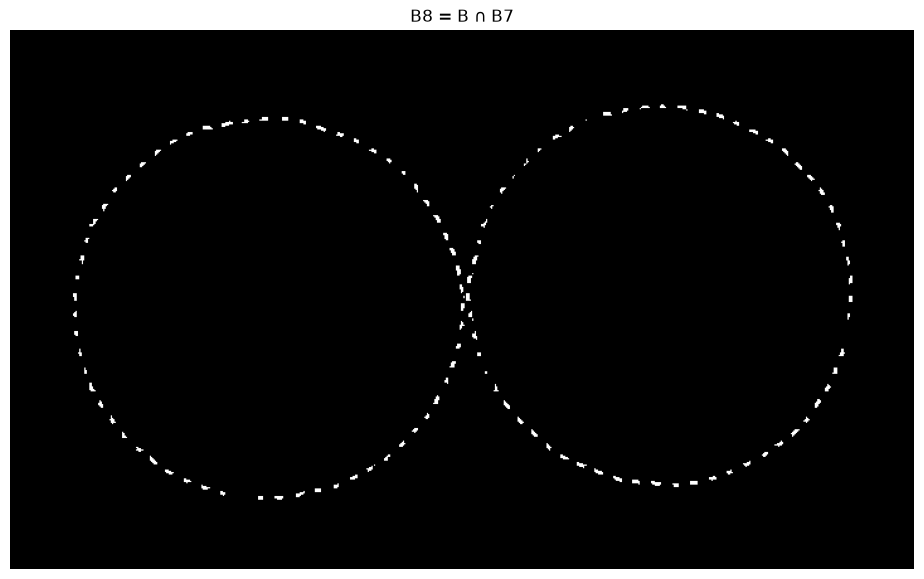

In [ ]:
B8 = cv2.bitwise_and(B, B7)
print("верхушек:", cv2.connectedComponentsWithStats(B8, 8)[0] - 1)

plt.figure(figsize=(12, 7))
plt.imshow(B8, "gray", vmin=0, vmax=255)
plt.title("B8 = B ∩ B7")
plt.axis("off")
plt.show()

## Сплошное кольцо

дефектов: 2


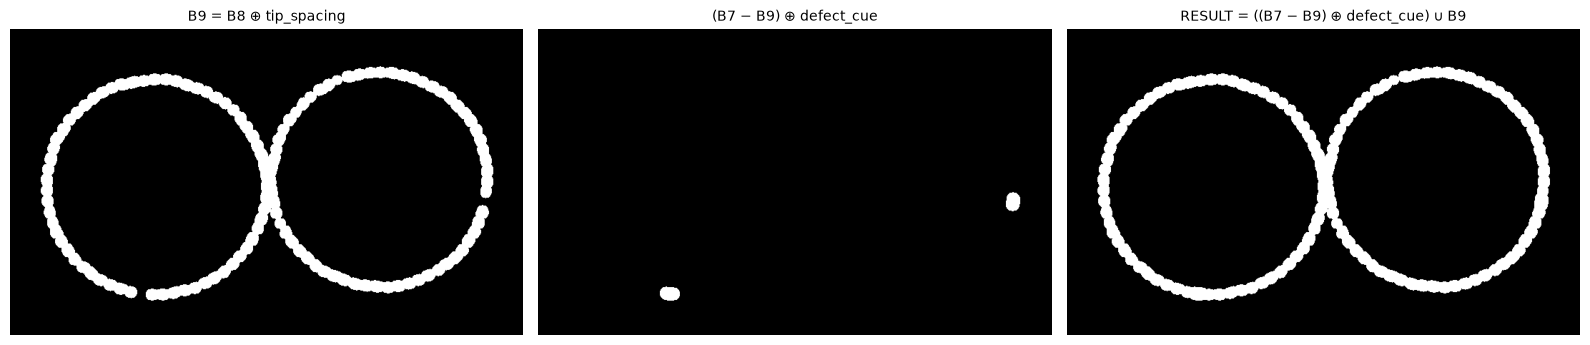

In [ ]:
B9 = cv2.dilate(B8, disk(tip_spacing))
defects = cv2.dilate(cv2.subtract(B7, B9), disk(defect_cue))
result = cv2.bitwise_or(defects, B9)
print("дефектов:", cv2.connectedComponentsWithStats(defects, 8)[0] - 1)

plt.figure(figsize=(16, 8))
for i, (title, img) in enumerate([("B9 = B8 ⊕ tip_spacing", B9),
                                  ("(B7 − B9) ⊕ defect_cue", defects),
                                  ("RESULT = ((B7 − B9) ⊕ defect_cue) ∪ B9", result)], start=1):
    plt.subplot(1, 3, i)
    plt.imshow(img, "gray", vmin=0, vmax=255)
    plt.title(title, fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Результат

дефект 1: (663, 241)
дефект 2: (183, 370)


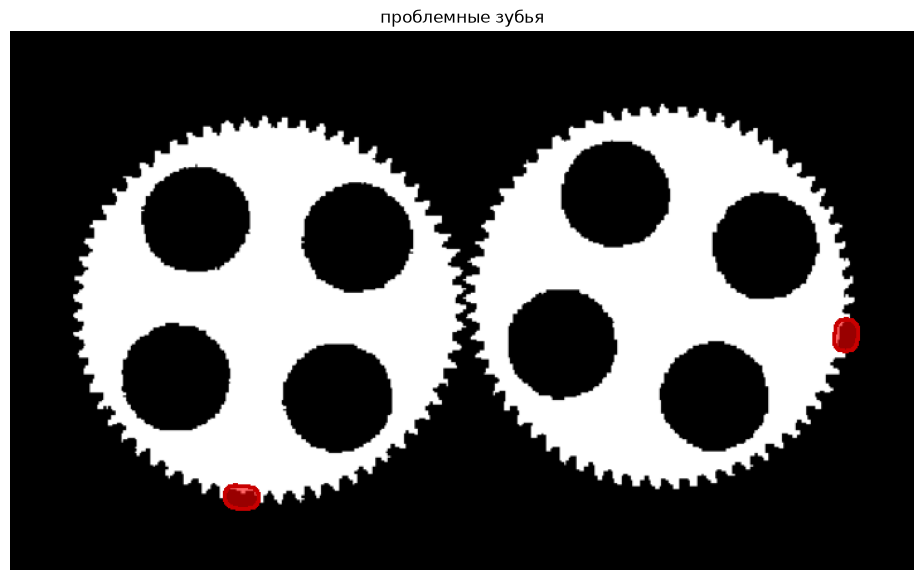

In [ ]:
marked = image.copy()
marked[defects > 0] = (0.4 * marked[defects > 0] + 0.6 * np.array([255, 0, 0])).astype(np.uint8)

contours, _ = cv2.findContours(defects, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(marked, contours, -1, (200, 0, 0), 2)

_, _, _, centers = cv2.connectedComponentsWithStats(defects, 8)
for i, (x, y) in enumerate(centers[1:], start=1):
    print(f"дефект {i}: ({x:.0f}, {y:.0f})")

plt.figure(figsize=(12, 7))
plt.imshow(marked)
plt.title("проблемные зубья")
plt.axis("off")
plt.show()